### Business Problem
Swiggy processes millions of food-delivery journeys across hundreds of cities every month. Accurate Estimated Time of Arrival (ETA) at order placement and during delivery is core to the customer experience — it affects conversion, cancellations, ratings, and retention. Today’s ETA accuracy suffers from many sources of uncertainty: highly variable traffic patterns, weather events, restaurant preparation variability, rider behaviour and skill, order batching/multiple deliveries, and city-specific operational constraints. Inaccurate ETAs cause:\

+ Reduced customer trust and lower repeat orders.

+ Increased cancellations and refund costs.

+ Higher support volume and operational interventions.


+ Sub-optimal rider allocation and increased rider idle or overtime costs.


### Problem Statement

+ Build a scalable, production-ready ML system to forecast order delivery times using geospatial, temporal, rider, weather, and restaurant data.

+ Deliver highly reliable initial ETAs to customers at checkout while continuously updating predictions dynamically as the order progresses.

+ Output point predictions alongside uncertainty estimates (confidence intervals) to better handle real-world operational delays.

+ Enable smarter platform decisions, including optimized rider allocation, reduced support volume, and improved customer retention.

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, PowerTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error,r2_score

from sklearn.model_selection import cross_val_score, KFold

import optuna


In [3]:
#loading the file

df = pd.read_csv(r"C:\Users\Sanju\Downloads\swiggy_demographic.csv")

In [3]:
#checking the info of the data

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45502 entries, 0 to 45501
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   rider_id              45502 non-null  str    
 1   age                   43648 non-null  float64
 2   ratings               43594 non-null  float64
 3   restaurant_latitude   41872 non-null  float64
 4   restaurant_longitude  41872 non-null  float64
 5   delivery_latitude     41872 non-null  float64
 6   delivery_longitude    41872 non-null  float64
 7   order_date            45502 non-null  str    
 8   weather               44977 non-null  str    
 9   traffic               44992 non-null  str    
 10  vehicle_condition     45502 non-null  int64  
 11  type_of_order         45502 non-null  str    
 12  type_of_vehicle       45502 non-null  str    
 13  multiple_deliveries   44509 non-null  float64
 14  festival              45274 non-null  str    
 15  city_type             44304 no

In [4]:
# checking the shape of the data

df.shape

(45502, 26)

In [5]:
df.head()

,rider_id,age,ratings,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,order_date,weather,traffic,...,time_taken,city_name,order_day,order_month,order_day_of_week,is_weekend,pickup_time_minutes,order_time_hour,order_time_of_day,distance
0,INDORES13DEL02,37.0,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,sunny,high,...,24,INDO,19,3,saturday,1,15.0,11.0,morning,3.025149
1,BANGRES18DEL02,34.0,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,stormy,jam,...,33,BANG,25,3,friday,0,5.0,19.0,evening,20.183530
2,BANGRES19DEL01,23.0,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,sandstorms,low,...,26,BANG,19,3,saturday,1,15.0,8.0,morning,1.552758
3,COIMBRES13DEL02,38.0,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,sunny,medium,...,21,COIMB,5,4,tuesday,0,10.0,18.0,evening,7.790401
4,CHENRES12DEL01,32.0,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,cloudy,high,...,30,CHEN,26,3,saturday,1,15.0,13.0,afternoon,6.210138


In [6]:
#statistical summary values of the numeric data

df.describe()

,age,ratings,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,vehicle_condition,multiple_deliveries,time_taken,order_day,order_month,is_weekend,pickup_time_minutes,order_time_hour,distance
count,43648.000000,43594.000000,41872.000000,41872.000000,41872.000000,41872.000000,45502.000000,44509.000000,45502.000000,45502.000000,45502.000000,45502.000000,43862.000000,43862.000000,41872.000000
mean,29.555008,4.635287,18.913696,76.921664,18.977356,76.985325,1.019406,0.744928,26.297591,13.811657,2.980726,0.274867,9.989399,17.423966,9.719296
std,5.761482,0.313827,5.467265,3.503107,5.469056,3.503260,0.835229,0.572488,9.386419,8.709540,0.546031,0.446452,4.087516,4.817856,5.602890
min,20.000000,2.500000,9.957144,72.768726,9.967144,72.778726,0.000000,0.000000,10.000000,1.000000,2.000000,0.000000,5.000000,0.000000,1.465067
25%,25.000000,4.500000,12.986047,73.897902,13.065996,73.940327,0.000000,0.000000,19.000000,6.000000,3.000000,0.000000,5.000000,15.000000,4.657655
50%,30.000000,4.700000,19.065838,76.618203,19.124049,76.662620,1.000000,1.000000,26.000000,13.000000,3.000000,0.000000,10.000000,19.000000,9.193014
75%,35.000000,4.900000,22.751234,78.368855,22.820040,78.405467,2.000000,1.000000,32.000000,20.000000,3.000000,1.000000,15.000000,21.000000,13.680920
max,39.000000,5.000000,30.914057,88.433452,31.054057,88.563452,3.000000,3.000000,54.000000,31.000000,4.000000,1.000000,15.000000,23.000000,20.969489


In [7]:
#checking for the duplicate records

df.duplicated().sum()

np.int64(0)

In [8]:
df.describe(include='str')

,rider_id,order_date,weather,traffic,type_of_order,type_of_vehicle,festival,city_type,city_name,order_day_of_week,order_time_of_day
count,45502,45502,44977,44992,45502,45502,45274,44304,45502,45502,45502
unique,1320,44,6,4,4,4,2,3,22,7,5
top,JAPRES11DEL02,15-03-2022,fog,low,snack,motorcycle,no,metropolitian,JAP,wednesday,night
freq,67,1190,7654,15477,11512,26427,44380,34029,3439,7077,18312


In [11]:
num_cols = ['age', 'ratings', 'restaurant_latitude', 'restaurant_longitude',
       'delivery_latitude', 'delivery_longitude', 'vehicle_condition',
       'multiple_deliveries', 'time_taken', 'order_day', 'order_month',
       'is_weekend', 'pickup_time_minutes', 'order_time_hour', 'distance']

In [12]:
cat_cols = ['rider_id', 'weather', 'traffic', 'type_of_order', 'type_of_vehicle',
       'festival', 'city_type', 'city_name', 'order_day_of_week',
       'order_time_of_day']

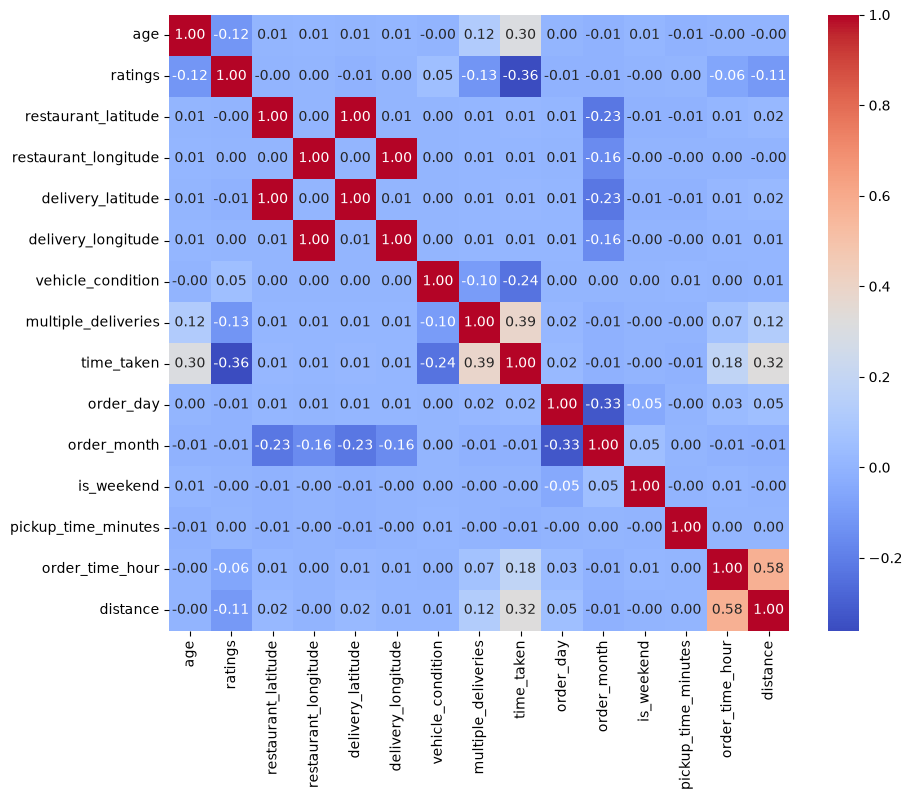

In [9]:
#checking the correlation using plot

plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap="coolwarm", fmt=".2f")
plt.show()

In [13]:
# Finding the correlation coefficients of independent variable to the target variable
correlations = df[num_cols].corr()['time_taken'].sort_values(ascending=False)
correlations

time_taken              1.000000
multiple_deliveries     0.387231
distance                0.320705
age                     0.303817
order_time_hour         0.184378
order_day               0.023676
delivery_latitude       0.013964
restaurant_latitude     0.011813
delivery_longitude      0.010084
restaurant_longitude    0.006720
is_weekend             -0.003141
pickup_time_minutes    -0.008478
order_month            -0.012354
vehicle_condition      -0.235125
ratings                -0.360980
Name: time_taken, dtype: float64

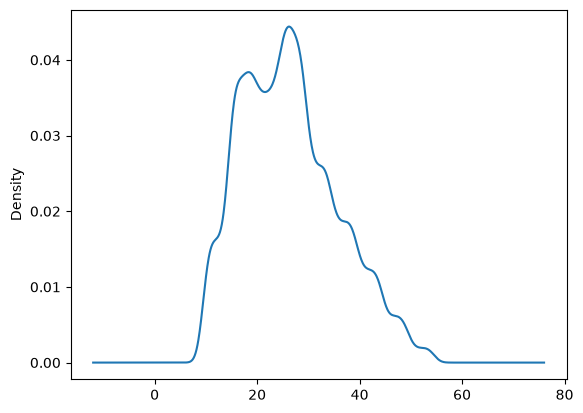

In [14]:
#checking the skewness of a target feature

df['time_taken'].plot(kind = 'kde');

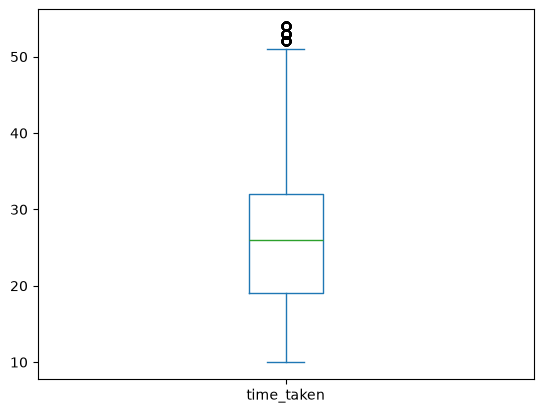

In [15]:
#checking if there is outliers in the targer feature

df['time_taken'].plot(kind = 'box');

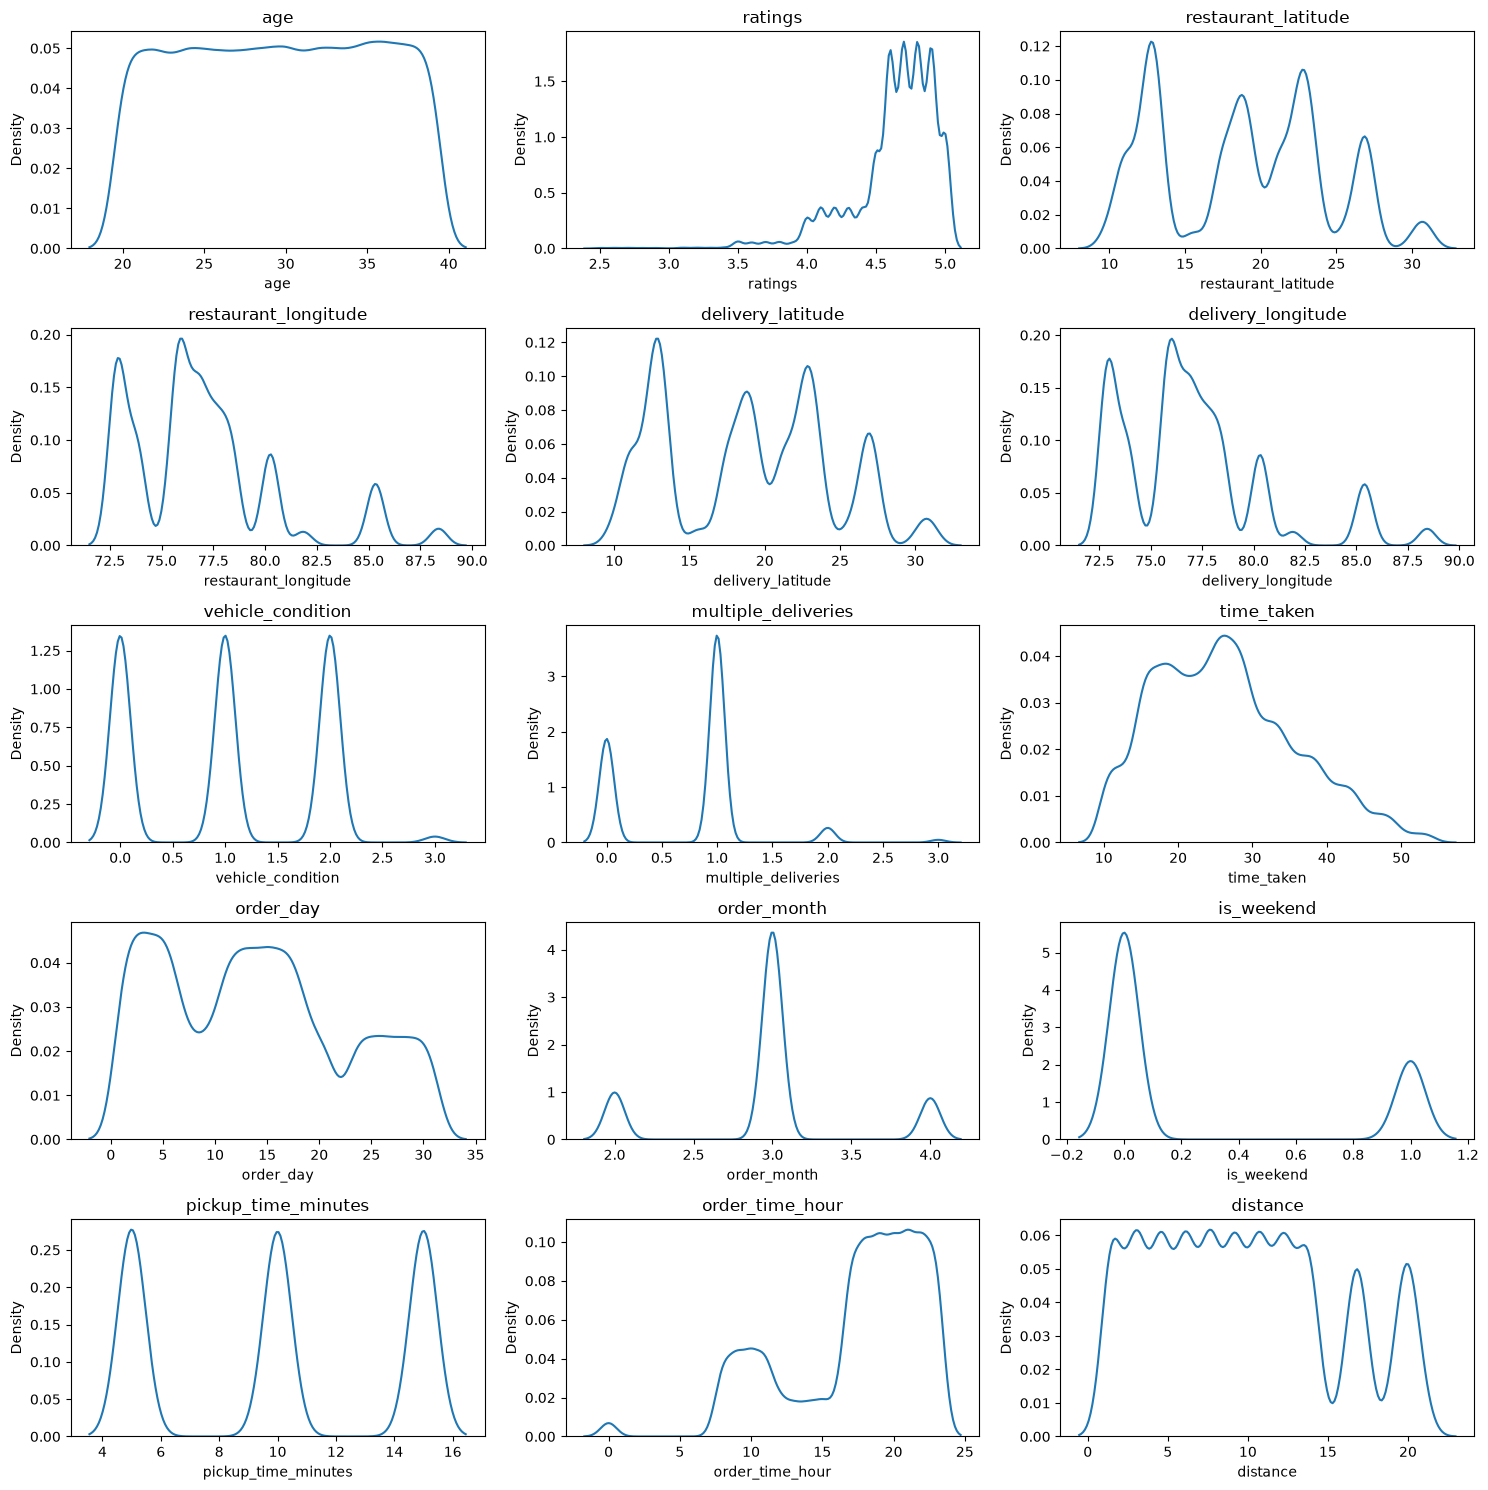

In [16]:
# Plotting kde plot to understand the distribution of the featutres
n_cols = len(num_cols)
plt.figure(figsize=(15, 3 * ((n_cols + 2) // 3)))  # 3 columns per row

for i, col in enumerate(num_cols, 1):
    plt.subplot((n_cols + 2) // 3, 3, i)
    sns.kdeplot(x=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

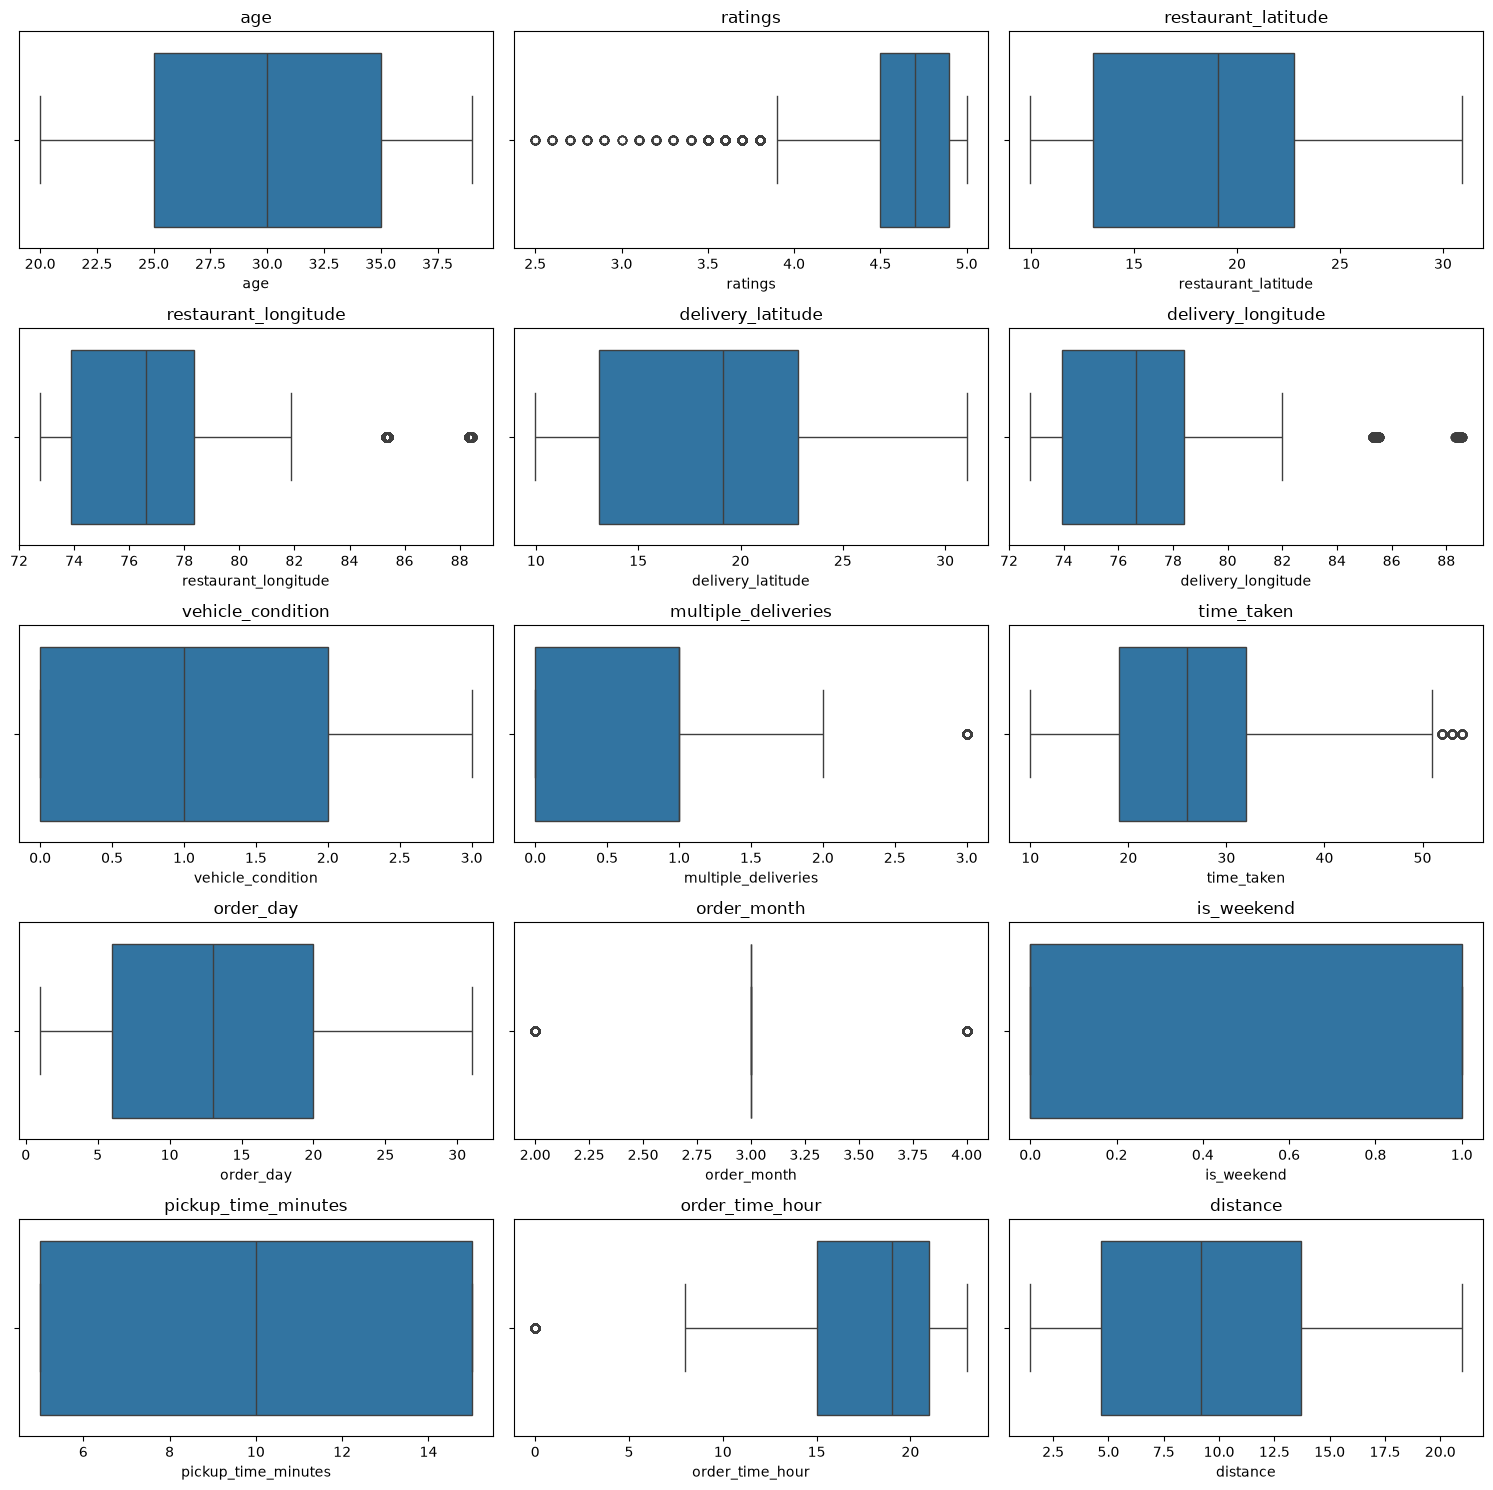

In [17]:
# plotting boxplot to check the outliers

n_cols = len(num_cols)
plt.figure(figsize=(15, 3 * ((n_cols + 2) // 3))) 

for i, col in enumerate(num_cols, 1):
    plt.subplot((n_cols + 2) // 3, 3, i)
    sns.boxplot(x=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

### Data Preprocessing

In [4]:
#dropping raider_id as it contains unique values
# dropping the columns restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude since already the distance is extarcted

# dropping order_date since the day momnth weekend has been extracted

# dropping city_name since there is city_type

df = df.drop(columns=['restaurant_latitude','restaurant_longitude','delivery_latitude','delivery_longitude','order_date','city_name','rider_id'])

In [5]:
df.shape

(45502, 19)

In [6]:
df.isna().sum()

age                    1854
ratings                1908
weather                 525
traffic                 510
vehicle_condition         0
type_of_order             0
type_of_vehicle           0
multiple_deliveries     993
festival                228
city_type              1198
time_taken                0
order_day                 0
order_month               0
order_day_of_week         0
is_weekend                0
pickup_time_minutes    1640
order_time_hour        1640
order_time_of_day         0
distance               3630
dtype: int64

In [7]:
num_col = ['age',
 'ratings', 'vehicle_condition',
 'multiple_deliveries',
 'order_day',
 'order_month',
 'is_weekend',
 'pickup_time_minutes',
 'order_time_hour',
 'distance']

In [8]:
numerical_transformer = Pipeline([('KNN Imputer',KNNImputer()),
                                 ('Standard Scaler',StandardScaler()),
                                 ('Power Transformer',PowerTransformer())])

In [9]:
numerical_transformer

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('KNN Imputer', ...), ('Standard Scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"missing_values missing_values: int, float, str, np.nan or None, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`should be set to np.nan, since `pd.NA` will be converted to np.nan.",nan
,"n_neighbors n_neighbors: int, default=5Number of neighboring samples to use for imputation.",5
,"weights weights: {'uniform', 'distance'} or callable, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- callable : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.",'uniform'
,"metric metric: {'nan_euclidean'} or callable, default='nan_euclidean'Distance metric for searching neighbors. Possible values:- 'nan_euclidean'- callable : a user-defined function which conforms to the definition of ``func_metric(x, y, *, missing_values=np.nan)``. `x` and `y` corresponds to a row (i.e. 1-D arrays) of `X` and `Y`, respectively. The callable should returns a scalar distance value.",'nan_euclidean'
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto theoutput of the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear on themissing indicator even if there are missing values at transform/testtime.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The im

In [10]:
nominal_cols = ['weather','type_of_vehicle','festival','is_weekend','order_day_of_week','order_time_of_day']

In [11]:
nominal_transformer = Pipeline([('Most frequent',SimpleImputer(strategy='most_frequent')),
                               ('(One Hot Encoding',OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

In [12]:
nominal_transformer

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Most frequent', ...), ('(One Hot Encoding', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'most_frequent'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictiv

In [13]:
ordinal_cols = ['traffic','city_type']

In [14]:
ord_categories = [['low', 'medium', 'high', 'jam'],
                 ['semi-urban', 'urban', 'metropolitian']]

In [15]:
ordinal_trasnformer = Pipeline([('Most Imputation',SimpleImputer(strategy='most_frequent')),
                               ('Ordinal Encoding',OrdinalEncoder(categories=ord_categories))])

In [16]:
ordinal_trasnformer

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Most Imputation', ...), ('Ordinal Encoding', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'most_frequent'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predicti

In [17]:
preprocessing = ColumnTransformer([('Numerical Transformer', numerical_transformer,num_col),
                   ('Nominal Transformer', nominal_transformer,nominal_cols),
                  ('Ordinal Transformer',ordinal_trasnformer,ordinal_cols)])

In [18]:
preprocessing

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numerical Transformer', ...), ('Nominal Transformer', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``

In [19]:
#Splitting the data

X = df.drop(columns='time_taken')
y = df['time_taken']

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=23)

### Model Building

In [24]:
knn = Pipeline([('Data Preprocessing',preprocessing),
               ('Model Building',KNeighborsRegressor(n_neighbors=5,weights='distance',p=1))])
knn.fit(X_train,y_train)
y_pred = knn.predict(X_test)
print(f'mean squared error: ',mean_squared_error(y_test,y_pred))
print(f'mean absolute error: ',mean_absolute_error(y_test,y_pred))
print(f'root mean squared error: ',root_mean_squared_error(y_test,y_pred))
print(f'r2 score: ',r2_score(y_test,y_pred))

mean squared error:  32.284517923962675
mean absolute error:  4.445594783922373
root mean squared error:  5.681946666765069
r2 score:  0.6368865763873918


In [25]:
lr = Pipeline([('Data Preprocessing',preprocessing),
               ('Model Building',LinearRegression())])
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)
print(f'mean squared error: ',mean_squared_error(y_test,y_pred))
print(f'mean absolute error: ',mean_absolute_error(y_test,y_pred))
print(f'root mean squared error: ',root_mean_squared_error(y_test,y_pred))
print(f'r2 score: ',r2_score(y_test,y_pred))

mean squared error:  38.24004904392469
mean absolute error:  4.927159083427088
root mean squared error:  6.183853898979559
r2 score:  0.5699029745416373


In [26]:
dt = Pipeline([('Data Preprocessing',preprocessing),
               ('Model Building',DecisionTreeRegressor())])
dt.fit(X_train,y_train)
y_pred = dt.predict(X_test)
print(f'mean squared error: ',mean_squared_error(y_test,y_pred))
print(f'mean absolute error: ',mean_absolute_error(y_test,y_pred))
print(f'root mean squared error: ',root_mean_squared_error(y_test,y_pred))
print(f'r2 score: ',r2_score(y_test,y_pred))

mean squared error:  30.548840786726732
mean absolute error:  4.171080101087792
root mean squared error:  5.527100576860053
r2 score:  0.6564082452279254


In [27]:
svr = Pipeline([('Data Preprocessing',preprocessing),
               ('Model Building',SVR())])
svr.fit(X_train,y_train)
y_pred = svr.predict(X_test)
print(f'mean squared error: ',mean_squared_error(y_test,y_pred))
print(f'mean absolute error: ',mean_absolute_error(y_test,y_pred))
print(f'root mean squared error: ',root_mean_squared_error(y_test,y_pred))
print(f'r2 score: ',r2_score(y_test,y_pred))

mean squared error:  25.88775001903544
mean absolute error:  4.020352771344339
root mean squared error:  5.088000591493228
r2 score:  0.7088328975151839


In [25]:
rf = Pipeline([('Data Preprocessing',preprocessing),
               ('Model Building',RandomForestRegressor())])
rf.fit(X_train,y_train)
y_pred = rf.predict(X_test)
print(f'mean squared error: ',mean_squared_error(y_test,y_pred))
print(f'mean absolute error: ',mean_absolute_error(y_test,y_pred))
print(f'root mean squared error: ',root_mean_squared_error(y_test,y_pred))
print(f'r2 score: ',r2_score(y_test,y_pred))

mean squared error:  16.11936405064157
mean absolute error:  3.1743137384170237
root mean squared error:  4.014892781960879
r2 score:  0.818700793963473


In [21]:
xgboost = Pipeline([('Data Preprocessing',preprocessing),
               ('Model Building',XGBRegressor())])
xgboost.fit(X_train,y_train)
y_pred = xgboost.predict(X_test)
print(f'mean squared error: ',mean_squared_error(y_test,y_pred))
print(f'mean absolute error: ',mean_absolute_error(y_test,y_pred))
print(f'root mean squared error: ',root_mean_squared_error(y_test,y_pred))
print(f'r2 score: ',r2_score(y_test,y_pred))

mean squared error:  16.067235946655273
mean absolute error:  3.17602801322937
root mean squared error:  4.008395671844482
r2 score:  0.819287121295929


### Cross Validating the model

In [24]:
xgboost = Pipeline([('Data Preprocessing',preprocessing),
               ('Model Building',XGBRegressor())])

kf = KFold(n_splits=5, shuffle=True, random_state=23)
scores = cross_val_score(xgboost, X_train, y_train, cv=kf, scoring='r2')

print("R2 scores for each fold:", scores)
print("Mean R2 score:", scores.mean())
print("Standard Deviation:", scores.std())

R2 scores for each fold: [0.81778622 0.80790997 0.81488478 0.81016612 0.80763149]
Mean R2 score: 0.8116757154464722
Standard Deviation: 0.004011279615820638


### Checking Bias-Varience Trade off of Random Forest 

In [26]:
#Train prediction
y_train_pred_rf = rf.predict(X_train)

#Test prediction
y_test_pred_rf = rf.predict(X_test)

#R2 Score
train_r2_rf = r2_score(y_train, y_train_pred_rf)
test_r2_rf = r2_score(y_test, y_test_pred_rf)

print("Train R2:", train_r2_rf)
print("Test R2:", test_r2_rf)

#RMSE
train_rmse_rf = root_mean_squared_error(y_train, y_train_pred_rf)
test_rmse_rf = root_mean_squared_error(y_test, y_test_pred_rf)

print("Train RMSE:", train_rmse_rf)
print("Test RMSE:", test_rmse_rf)

Train R2: 0.9741175542818433
Test R2: 0.818700793963473
Train RMSE: 1.5082843677766287
Test RMSE: 4.014892781960879


### Checking Bias-Varience Trade off of XGboost

In [28]:
#Train prediction
y_train_pred_XG = xgboost.predict(X_train)

#Test prediction
y_test_pred_XG = xgboost.predict(X_test)

#R2 Score
train_r2_XG = r2_score(y_train, y_train_pred_XG)
test_r2_XG = r2_score(y_test, y_test_pred_XG)

print("Train R2:", train_r2_XG)
print("Test R2:", test_r2_XG)

#RMSE
train_rmse_XG = root_mean_squared_error(y_train, y_train_pred_XG)
test_rmse_XG = root_mean_squared_error(y_test, y_test_pred_XG)

print("Train RMSE:", train_rmse_XG)
print("Test RMSE:", test_rmse_XG)

Train R2: 0.8680580258369446
Test R2: 0.819287121295929
Train RMSE: 3.405431032180786
Test RMSE: 4.008395671844482


+ After checking the bias variance trade off scores between Random Forest Model and XGboost Model, the XGBoost model has less score.
+ Based on the score I chose the XGBoost model 

### Hyper Parameter Tuning

In [34]:
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000, step=100),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'gamma': trial.suggest_float('gamma', 1e-8, 1.0, log=True),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'random_state': 23
    }
    
    model = Pipeline([
        ('Data Preprocessing', preprocessing),
        ('Model Building', XGBRegressor(**params))
    ])
    
    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_test)
    
    score = r2_score(y_test, y_pred)
    return score

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=50)

print("Best Hyperparameters:", study.best_params)
print("Best R2 Score:", study.best_value)

[I 2026-10-06 18:59:28,082] A new study created in memory with name: no-name-08154cf1-5474-451d-bd77-c1ad567a385c
[I 2026-10-06 18:59:46,701] Trial 0 finished with value: 0.47509706020355225 and parameters: {'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.011217567497795664, 'subsample': 0.7847170585722963, 'colsample_bytree': 0.6384316898573766, 'gamma': 0.016912529706868226, 'min_child_weight': 4}. Best is trial 0 with value: 0.47509706020355225.
[I 2026-10-06 19:00:13,324] Trial 1 finished with value: 0.811124861240387 and parameters: {'n_estimators': 1000, 'max_depth': 5, 'learning_rate': 0.01954119141163191, 'subsample': 0.5446426148261856, 'colsample_bytree': 0.9435785092595366, 'gamma': 8.93222221009303e-06, 'min_child_weight': 9}. Best is trial 1 with value: 0.811124861240387.
[I 2026-10-06 19:00:37,843] Trial 2 finished with value: 0.8058465123176575 and parameters: {'n_estimators': 500, 'max_depth': 4, 'learning_rate': 0.1491588140871315, 'subsample': 0.84945409295219

Best Hyperparameters: {'n_estimators': 400, 'max_depth': 10, 'learning_rate': 0.014843570070313342, 'subsample': 0.7771004024937227, 'colsample_bytree': 0.8848066401046462, 'gamma': 0.003035064379101338, 'min_child_weight': 9}
Best R2 Score: 0.826546847820282


### Building the model using Hyper Parameters

In [59]:
xgboost = Pipeline([
    ('Data Preprocessing', preprocessing),
    ('Model Building', XGBRegressor(
        n_estimators=400,
        max_depth=10,
        learning_rate=0.014843570070313342,
        subsample=0.7771004024937227,
        colsample_bytree=0.8848066401046462,
        gamma=0.003035064379101338,
        min_child_weight=9
    ))
])

xgboost.fit(X_train, y_train)
y_pred = xgboost.predict(X_test)

print(f'mean squared error: ', mean_squared_error(y_test, y_pred))
print(f'mean absolute error: ', mean_absolute_error(y_test, y_pred))
print(f'root mean squared error: ', root_mean_squared_error(y_test, y_pred))
print(f'r2 score: ', r2_score(y_test, y_pred))

mean squared error:  15.03415298461914
mean absolute error:  3.0844228267669678
root mean squared error:  3.877389907836914
r2 score:  0.8309065103530884


In [60]:
import pickle

with open(r'C:\Users\Sanju\streamlit\Swiggy Delivery\swiggy.pkl','wb') as f:
    pickle.dump(xgboost,f)

In [58]:
# Clean trailing spaces from categorical features
for col in X_train.select_dtypes(include='object').columns:
    X_train[col] = X_train[col].astype(str).str.strip()
    X_test[col] = X_test[col].astype(str).str.strip()

C:\Users\Sanju\AppData\Local\Temp\ipykernel_3588\3888180920.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in X_train.select_dtypes(include='object').columns:
